# M8230: Diferenční tabulka a metoda nejmenších čtverců

Máme k dispozici modelová naměřená data, která obsahují malou chybu měření.

Vaším úkolem je:

- prozkoumat naměřené hodnoty,
- využít diference k odhalení jejich struktury,
- navrhnout vhodný model,
- odhadnout jeho parametry metodou nejmenších čtverců,
- posoudit, jak dobře model data popisuje.

Postup řešení není předem připraven. K vyhledání vhodné syntaxe v R můžete využít AI. Získaný kód je však potřeba zkontrolovat, upravit pro naše data a interpretovat jeho výstupy.

## Pravidla práce s AI

AI používejte zejména jako pomoc se syntaxí a vysvětlením jednotlivých příkazů.

Příklady vhodných dotazů:

- Jak v R vykreslím diskrétní data?
- Jak opakovaně vypočítám diference vektoru?
- Jak v R odhadnu parametry zvoleného modelu metodou nejmenších čtverců?
- Jak porovnám naměřené a odhadnuté hodnoty?

Rozhodnutí o tom, které diference zkoumat a jaký model zvolit, musí vycházet z vašeho vlastního pozorování.


In [25]:
library(ggplot2)

In [26]:
# Pro výpočty budeme používat základní funkce jazyka R
# a pro grafy balíček ggplot2.

## 1. Naměřená data

Proměnná `t` obsahuje časové indexy a proměnná `y` naměřené hodnoty.

In [27]:
t <- 0:8

y <- c(
  10.0,
  12.1,
  15.9,
  28.1,
  53.9,
  100.1,
  171.9,
  276.1,
  418.0
)

cat("t =", t, "\n")
cat("y =", y, "\n")

t = 0 1 2 3 4 5 6 7 8 
y = 10 12.1 15.9 28.1 53.9 100.1 171.9 276.1 418 


## 2. První průzkum dat

Vhodným způsobem data znázorněte a popište jejich základní chování.

### Záznam

a) **Jak jste data znázornili:** data jsme znazornily pomoci bodoveho a caroveho grafu, kde na vodorovne ose je casovy index t a na svisle ose namerena hodnota y

b) **Co lze ze znázornění pozorovat:** hodnoty y s rostoucim casem t monotonne rostou, pricemz rychlost rustu se vyrazne zrychluje

c) **Jaký typ chování data na první pohled připomínají:** polynomickou funkci vyssiho stupne



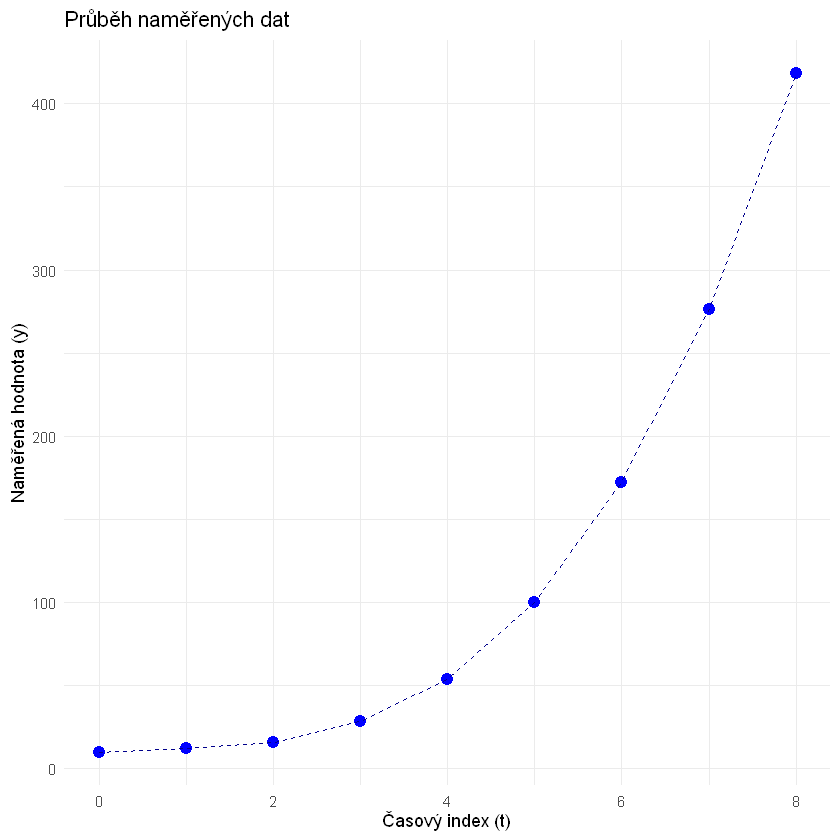

In [38]:
df <- data.frame(t = t, y = y)

ggplot(df, aes(x = t, y = y)) +
  geom_point(color = "blue", size = 3) +
  geom_line(color = "darkblue", linetype = "dashed") +
  labs(
    title = "Průběh naměřených dat",
    x = "Časový index (t)",
    y = "Naměřená hodnota (y)"
  ) +
  theme_minimal()

## 3. Zkoumání diferencí

Vypočítejte postupně diference naměřených hodnot.

Sami rozhodněte:

- kolik řádů diferencí potřebujete prozkoumat,
- jak výsledky přehledně zobrazit,
- která diference se začne chovat přibližně pravidelně.

### Záznam

a) **Které řády diferencí jste vypočítali:** 1.-5.

b) **Která diference se začala chovat přibližně pravidelně:** priblizne 5.

c) **V čem toto pravidelné chování spočívá:** hodnoty se zacaly pohzbovat v malem rozmezi (kolem 6) 

d) **Co z tohoto pozorování usuzujete o vhodném modelu:**  bude zadan polynomem 3. stupne

e) **Proč není pozorované chování úplně přesné:** kvuli chybam v mereni

In [39]:
d1 <- diff(y)
d2 <- diff(y, differences = 2)
d3 <- diff(y, differences = 3)
d4 <- diff(y, differences = 4)

cat("1. diference:", round(d1, 2), "\n")
cat("2. diference:", round(d2, 2), "\n")
cat("3. diference:", round(d3, 2), "\n")
cat("4. diference:", round(d4, 2), "\n")


1. diference: 2.1 3.8 12.2 25.8 46.2 71.8 104.2 141.9 
2. diference: 1.7 8.4 13.6 20.4 25.6 32.4 37.7 
3. diference: 6.7 5.2 6.8 5.2 6.8 5.3 
4. diference: -1.5 1.6 -1.6 1.6 -1.5 


## 4. Návrh modelu

Na základě předchozího zkoumání zvolte vhodný model.

Formulujte ho matematicky a zdůvodněte jeho volbu ještě před odhadem parametrů.

### Záznam

a) **Zvolený typ modelu:** polynom 3. stupne

b) **Matematický zápis modelu:** y(t) = a*t^3 + b*t^2 + c*t + d

c) **Proč jste zvolili právě tento model:** u 3. diference byly hodnoty nejbliz u sebe, melz nejmensi rozdil a pak uz zacaly oscilovat

## 5. Odhad parametrů metodou nejmenších čtverců

Odhadněte parametry zvoleného modelu metodou nejmenších čtverců.

K nalezení vhodné syntaxe můžete využít AI. Zkontrolujte, v jakém pořadí R vypisuje odhadnuté koeficienty.

### Záznam

a) **Použitý příkaz nebo postup:** lm() - linearni model

b) **Odhadnuté parametry:** a = 1, b = -2 (-1,998), c = 3 (2,986), d = 10,3

c) **Výsledný odhadnutý model:**  y(t) = t^3 - 1.998*t^2 + 2.986*t + 10.027

In [ ]:
#lm() znazornuje linearni model, ktery se snazi najit koeficienty krivky, aby soucet ctvercu odchylek od hodnot byl co nejmensi
# vlnovka znamena zavisi na
# raw = TRUE znamena aby pouzil obycejne mocniny a ne ortogonalni polynomy
model <- lm(y ~ poly(t, degree = 3, raw = TRUE))
summary(model)



Call:
lm(formula = y ~ poly(t, degree = 3, raw = TRUE))

Residuals:
       1        2        3        4        5        6        7        8 
-0.02727  0.08485 -0.10649  0.09870 -0.09957  0.09870 -0.10649  0.08485 
       9 
-0.02727 

Coefficients:
                                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)                      10.027273   0.108032   92.82 2.75e-09 ***
poly(t, degree = 3, raw = TRUE)1  2.986147   0.124684   23.95 2.36e-06 ***
poly(t, degree = 3, raw = TRUE)2 -1.998268   0.037645  -53.08 4.49e-08 ***
poly(t, degree = 3, raw = TRUE)3  1.000000   0.003088  323.85 5.33e-12 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.1166 on 5 degrees of freedom
Multiple R-squared:      1,	Adjusted R-squared:      1 
F-statistic: 4.013e+06 on 3 and 5 DF,  p-value: 2.264e-16


## 6. Porovnání modelu s daty

Znázorněte v jednom grafu:

- původní naměřené hodnoty,
- hodnoty odhadnutého modelu.

Zvolte takové znázornění, ze kterého bude dobře vidět, jak model data popisuje.

### Záznam

a) **Jak jste data a model znázornili:** puvodni namerena data jsem zobrazila jako cervene body a model jako modrou caru

b) **Prochází model přesně všemi naměřenými body:** odchylka je minimalni, na obrazku to vypada, ze prochazi

c) **Ve kterých částech se model a data liší nejvíce:** t = 2 a t = 6

t,y,y_hat
<int>,<dbl>,<dbl>
0,10.0,10.02727
1,12.1,12.01515
2,15.9,16.00649
3,28.1,28.00130
4,53.9,53.99957
5,100.1,100.00130
6,171.9,172.00649
7,276.1,276.01515
8,418.0,418.02727


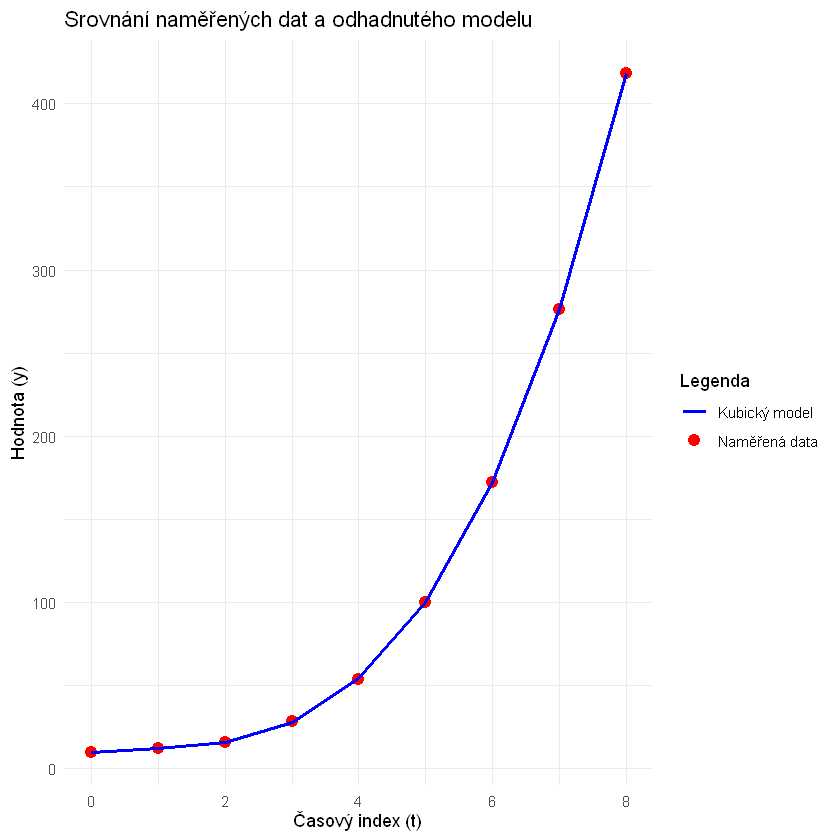

In [40]:
df$y_hat <- predict(model)
ggplot(df, aes(x = t)) +
  geom_point(aes(y = y, color = "Naměřená data"), size = 3) +
  geom_line(aes(y = y_hat, color = "Kubický model"), size = 1) +
  scale_color_manual(values = c("Naměřená data" = "red", "Kubický model" = "blue")) +
  labs(
    title = "Srovnání naměřených dat a odhadnutého modelu",
    x = "Časový index (t)",
    y = "Hodnota (y)",
    color = "Legenda"
  ) +
  theme_minimal()

  df

## 7. Vyhodnocení kvality modelu

Zvolte alespoň jeden způsob, jak numericky nebo graficky vyhodnotit rozdíly mezi naměřenými a odhadnutými hodnotami.

K nalezení vhodného postupu můžete využít AI.

### Záznam

a) **Jak jste rozdíly mezi daty a modelem vyhodnotili:** rozdily jsem vyhodnotila pomoci koeficientu determinace (R^2), stredni kvadraticke chyby (rmse) a grafickym znazornenim rezidui (odchylek y - y_hat)

b) **Jaký výsledek jste získali:** koeficient determinace vysel cca 1, takze model vysvetluje skoro presne hodnoty, rmse je 0.1166 a rezidua se pohybuji v malem rozemzi od -0.106 do 0.098

c) **Považujete model za vhodný:** ano model je velmi dobry a rezidua jsou velmi mala

d) **Jaké jsou limity vašeho závěru:** zaver plati pouze pro casovy interval 0-8, mimo interval muze mit realny proces jiny prubeh

Koeficient determinace (R^2): 1 


Střední kvadratická chyba (RMSE): 0.0869 


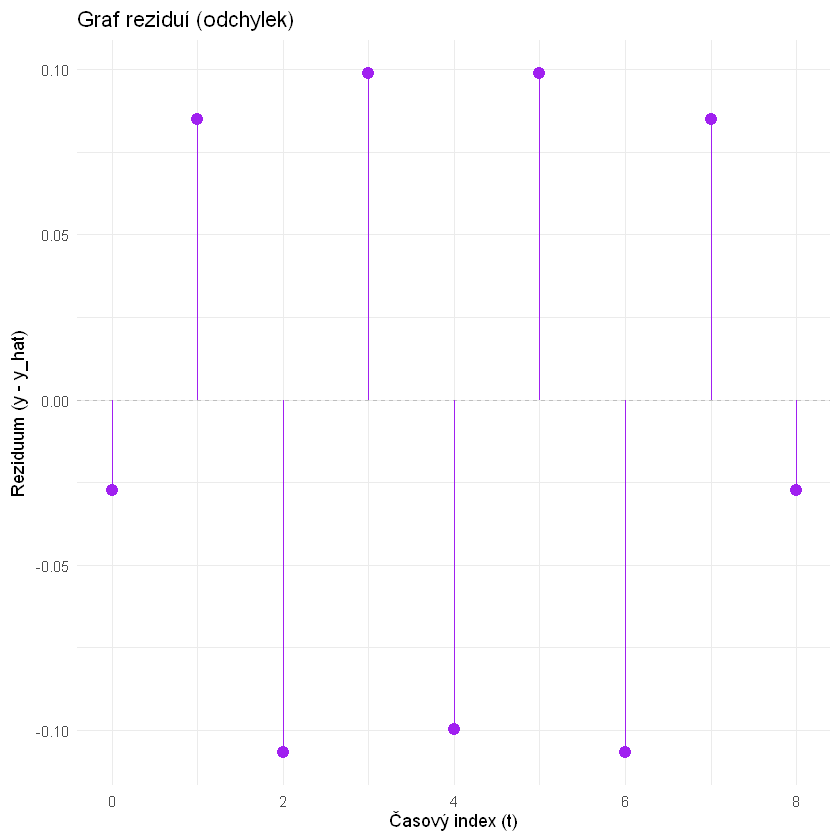

In [ ]:
residia <- residuals(model) #rozdil y - y_hat
r_squared <- summary(model)$r.squared # udava, jak moc dobre model vystihuje chovani dat
rmse <- sqrt(mean(residia^2)) #prumerna velikost odchylky modelu vyjadrena v prvotnich jednotkach

cat("Koeficient determinace (R^2):", round(r_squared, 6), "\n")
cat("Střední kvadratická chyba (RMSE):", round(rmse, 4), "\n")

df_res <- data.frame(t = t, residia = residia)

ggplot(df_res, aes(x = t, y = residia)) +
  geom_hline(yintercept = 0, linetype = "dashed", color = "gray") +
  geom_point(color = "purple", size = 3) +
  geom_segment(aes(xend = t, yend = 0), color = "purple") +
  labs(
    title = "Graf reziduí (odchylek)",
    x = "Časový index (t)",
    y = "Reziduum (y - y_hat)"
  ) +
  theme_minimal()

## 8. Záznam práce s AI

a) **Na co jste se AI zeptali:**

b) **Jakou odpověď nebo kód jste získali:**

c) **Co jste museli upravit pro naše data:**

d) **Jak jste ověřili, že kód funguje správně:**

e) **V čem vám AI pomohla a v čem jste museli rozhodnout sami:**

# Závěr

a) **Která informace z diferenční tabulky byla pro volbu modelu nejdůležitější:** priblizna konstantnost hodnot ve 3. diferencich

b) **Jaký model jste nakonec zvolili:** kubicky

c) **Jak dobře model popisuje naměřená data:** vyborne

d) **Jak se chyba měření projevila ve vyšších diferencích:** oscilaci

e) **Co byste při dalším zkoumání udělali jinak nebo doplnili:** doplnit vice namerenych bodu mimo interval 0-8